# Online Shopping Purchase Prediction

Predict whether an online shopping session ends in a purchase (`Revenue`). This notebook is the single source of truth for Tasks 1–6. It uses only the labeled training data through model selection; the held-out test CSV is loaded only in Task 6 to create the final submission.

## Imports and reproducibility

In [1]:
from IPython.display import display
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, make_scorer,
                             precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
N_SPLITS = 5
TARGET = 'Revenue'
ID_COLUMN = 'ID'
PROJECT_ROOT = (Path(__file__).resolve().parents[1] if '__file__' in globals()
                else Path.cwd().parent if Path.cwd().name == 'models' else Path.cwd())

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

## Task 1 — Explore and prepare the training data

Training shape: (9247, 19)


,ID,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,1,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,3,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
2,4,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
3,7,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
4,9,0,0.0,0,0.0,2,37.000000,0.00,0.10,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False


,count,mean,std,min,25%,50%,75%,max
Administrative,9247.0,2.314372,3.319935,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,9247.0,81.168776,179.593423,0.0,0.000000,8.000000,92.550000,3398.750000
Informational,9247.0,0.502433,1.272332,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,9247.0,34.517405,141.310276,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,9247.0,31.358170,43.539969,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,9247.0,1181.847920,1908.101262,0.0,181.416667,598.250000,1464.986002,63973.522230
BounceRates,9247.0,0.022268,0.048680,0.0,0.000000,0.003030,0.016834,0.200000
ExitRates,9247.0,0.043231,0.048835,0.0,0.014286,0.025088,0.050000,0.200000
PageValues,9247.0,5.983551,18.753351,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,9247.0,0.063307,0.201943,0.0,0.000000,0.000000,0.000000,1.000000


Missing values: 0
Duplicate rows: 0


,count,share
Revenue,,
False,7816,0.845247
True,1431,0.154753


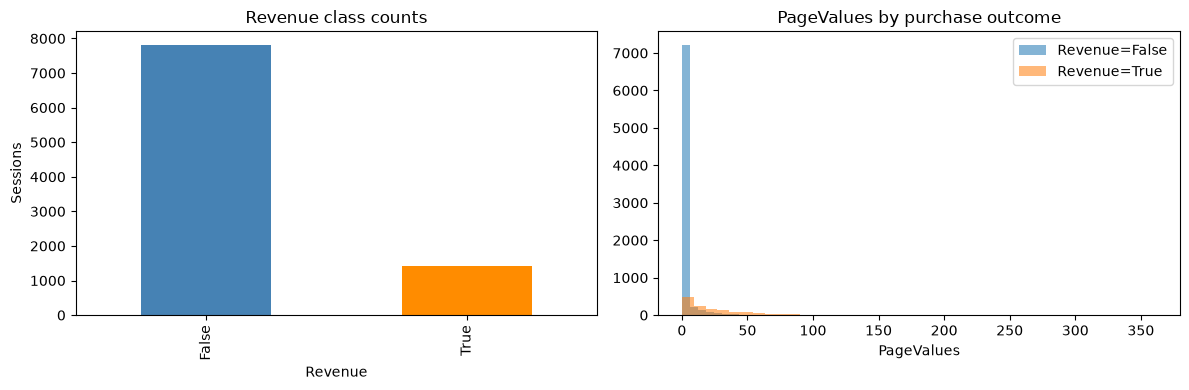

In [2]:
# Load only labeled training data. The test file remains untouched until Task 6.
df_train = pd.read_csv(PROJECT_ROOT / 'data' / 'challenge2_train.csv')

assert TARGET in df_train.columns, 'Training data must contain Revenue.'
assert df_train[ID_COLUMN].is_unique and df_train[ID_COLUMN].notna().all(), 'IDs must be unique and non-missing.'

print('Training shape:', df_train.shape)
display(df_train.head())
display(df_train.drop(columns=[ID_COLUMN, TARGET]).describe().T)
print('Missing values:', int(df_train.isna().sum().sum()))
print('Duplicate rows:', int(df_train.duplicated().sum()))

class_counts = df_train[TARGET].value_counts().rename_axis(TARGET).to_frame('count')
class_counts['share'] = class_counts['count'] / len(df_train)
display(class_counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts['count'].plot(kind='bar', ax=axes[0], color=['steelblue', 'darkorange'])
axes[0].set_title('Revenue class counts'); axes[0].set_xlabel('Revenue'); axes[0].set_ylabel('Sessions')
for label, group in df_train.groupby(TARGET):
    axes[1].hist(group['PageValues'], bins=40, alpha=0.55, label=f'Revenue={label}')
axes[1].set_title('PageValues by purchase outcome'); axes[1].set_xlabel('PageValues'); axes[1].legend()
plt.tight_layout(); plt.show()

`ID` identifies a session and is excluded from predictors. `Month`, visitor/device/browser/region/traffic codes, and `Weekend` are categorical; page counts, durations, rates, `PageValues`, and `SpecialDay` are numeric. All learned preprocessing remains inside pipelines so each cross-validation fold learns from its own training rows only.

In [3]:
X = df_train.drop(columns=[ID_COLUMN, TARGET])
y = df_train[TARGET].astype(bool)

categorical_columns = ['Month', 'OperatingSystems', 'Browser', 'Region',
                       'TrafficType', 'VisitorType', 'Weekend']
numeric_columns = [column for column in X.columns if column not in categorical_columns]
print('Categorical columns:', categorical_columns)
print('Numeric columns:', numeric_columns)

def make_preprocessor(numeric_features):
    return ColumnTransformer([
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical_columns),
        ('numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), numeric_features),
    ])

Categorical columns: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Numeric columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


## Task 2 — Validation strategy

In [4]:
# Every baseline comparison and Grid Search uses these same shuffled, stratified folds.
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1': make_scorer(f1_score, pos_label=True, zero_division=0),
    'precision': make_scorer(precision_score, pos_label=True, zero_division=0),
    'recall': make_scorer(recall_score, pos_label=True, zero_division=0),
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision',
}

fold_summary = []
for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y), start=1):
    fold_summary.append({
        'fold': fold, 'train_rows': len(train_idx), 'validation_rows': len(valid_idx),
        'train_positive_rate': y.iloc[train_idx].mean(),
        'validation_positive_rate': y.iloc[valid_idx].mean(),
    })
display(pd.DataFrame(fold_summary).round(4))
print('Primary metric: F1 for Revenue=True')
print('Supporting metrics: precision, recall, ROC AUC, average precision, and confusion matrix')

,fold,train_rows,validation_rows,train_positive_rate,validation_positive_rate
0,1,7397,1850,0.1548,0.1546
1,2,7397,1850,0.1547,0.1551
2,3,7398,1849,0.1548,0.1547
3,4,7398,1849,0.1548,0.1547
4,5,7398,1849,0.1548,0.1547


Primary metric: F1 for Revenue=True
Supporting metrics: precision, recall, ROC AUC, average precision, and confusion matrix


## Task 3 — Compare the required baseline models

In [5]:
def evaluate_model(name, estimator, stage):
    started = time.perf_counter()
    result = cross_validate(estimator, X, y, cv=cv, scoring=scoring,
                            return_train_score=True, n_jobs=-1, error_score='raise')
    return {
        'Model': name, 'Stage': stage,
        'Train_F1': result['train_f1'].mean(),
        'CV_F1': result['test_f1'].mean(),
        'CV_F1_std': result['test_f1'].std(),
        'CV_Precision': result['test_precision'].mean(),
        'CV_Recall': result['test_recall'].mean(),
        'CV_ROC_AUC': result['test_roc_auc'].mean(),
        'CV_Average_Precision': result['test_average_precision'].mean(),
        'F1_Gap': result['train_f1'].mean() - result['test_f1'].mean(),
        'Time_sec': time.perf_counter() - started,
    }

baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB(),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Support Vector Machine': SVC(random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
}

baseline_pipelines = {
    name: Pipeline([('preprocess', make_preprocessor(numeric_columns)), ('model', model)])
    for name, model in baseline_models.items()
}
baseline_results = [evaluate_model(name, pipeline, 'Baseline')
                    for name, pipeline in baseline_pipelines.items()]
baseline_df = pd.DataFrame(baseline_results).sort_values('CV_F1', ascending=False).reset_index(drop=True)
display(baseline_df.round(4))

,Model,Stage,Train_F1,CV_F1,CV_F1_std,CV_Precision,CV_Recall,CV_ROC_AUC,CV_Average_Precision,F1_Gap,Time_sec
0,Gradient Boosting,Baseline,0.7351,0.6607,0.0264,0.7128,0.6163,0.9314,0.7487,0.0744,1.3297
1,Random Forest,Baseline,1.0000,0.6298,0.0252,0.7711,0.5325,0.9244,0.7475,0.3702,1.9477
2,Support Vector Machine,Baseline,0.6635,0.5970,0.0180,0.7504,0.4968,0.8810,0.6963,0.0665,4.4182
3,Decision Tree,Baseline,1.0000,0.5614,0.0301,0.5597,0.5639,0.7413,0.3838,0.4386,0.1961
4,Logistic Regression,Baseline,0.5239,0.5155,0.0257,0.7519,0.3934,0.8957,0.6531,0.0084,1.9842
5,K-Nearest Neighbors,Baseline,0.6049,0.4927,0.0143,0.6784,0.3878,0.7972,0.4947,0.1122,1.9420
6,Naive Bayes,Baseline,0.3001,0.2984,0.0054,0.1759,0.9839,0.7084,0.2633,0.0016,1.3036


## Task 4 — Feature engineering and Grid Search

In [6]:
# These row-wise features learn nothing from the data, so they are safe inside every CV fold.
def add_features(frame):
    data = frame.copy()
    data['TotalPages'] = data['Administrative'] + data['Informational'] + data['ProductRelated']
    data['TotalDuration'] = (data['Administrative_Duration'] + data['Informational_Duration']
                             + data['ProductRelated_Duration'])
    data['AvgDurPerPage'] = data['TotalDuration'] / (data['TotalPages'] + 1)
    data['ProdDurPerPage'] = data['ProductRelated_Duration'] / (data['ProductRelated'] + 1)
    data['HasPageValue'] = (data['PageValues'] > 0).astype(int)
    data['PageValuePerProduct'] = data['PageValues'] / (data['ProductRelated'] + 1)
    data['ProductShare'] = data['ProductRelated'] / (data['TotalPages'] + 1)
    skewed = ['Administrative', 'Administrative_Duration', 'Informational',
              'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
              'PageValues', 'TotalPages', 'TotalDuration', 'AvgDurPerPage',
              'ProdDurPerPage', 'PageValuePerProduct']
    data[skewed] = np.log1p(data[skewed].clip(lower=0))
    return data

engineered_numeric_columns = [column for column in add_features(X.head()).columns
                            if column not in categorical_columns]

def make_engineered_pipeline(model):
    return Pipeline([
        ('features', FunctionTransformer(add_features, validate=False)),
        ('preprocess', make_preprocessor(engineered_numeric_columns)),
        ('model', model),
    ])

# Tune selected, complementary model families with positive-class F1 as the refit metric.
tuning_specs = {
    'Logistic Regression': (LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        {'model__C': [0.03, 0.1, 0.3, 1, 3], 'model__class_weight': [None, 'balanced']}),
    'Support Vector Machine': (SVC(random_state=RANDOM_STATE),
        {'model__C': [0.3, 1, 3], 'model__gamma': ['scale', 0.01],
         'model__class_weight': [None, 'balanced']}),
    'Random Forest': (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
        {'model__max_features': ['sqrt', 0.3], 'model__min_samples_leaf': [1, 3, 5, 10],
         'model__class_weight': [None, 'balanced_subsample']}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE),
        {'model__n_estimators': [150, 300], 'model__learning_rate': [0.03, 0.1],
         'model__max_depth': [2, 3, 4], 'model__subsample': [0.8, 1.0]}),
}

searches = {}
tuned_rows = []
for name, (model, grid) in tuning_specs.items():
    search = GridSearchCV(make_engineered_pipeline(model), grid, scoring=scoring,
                          refit='f1', cv=cv, n_jobs=-1, return_train_score=True,
                          error_score='raise')
    search.fit(X, y)
    searches[name] = search
    best = search.best_index_
    results = search.cv_results_
    tuned_rows.append({
        'Model': name, 'Stage': 'Tuned + engineered',
        'Train_F1': results['mean_train_f1'][best], 'CV_F1': results['mean_test_f1'][best],
        'CV_F1_std': results['std_test_f1'][best],
        'CV_Precision': results['mean_test_precision'][best],
        'CV_Recall': results['mean_test_recall'][best],
        'CV_ROC_AUC': results['mean_test_roc_auc'][best],
        'CV_Average_Precision': results['mean_test_average_precision'][best],
        'F1_Gap': results['mean_train_f1'][best] - results['mean_test_f1'][best],
        'Time_sec': results['mean_fit_time'][best] * N_SPLITS,
        'Best_parameters': search.best_params_,
    })

tuned_df = pd.DataFrame(tuned_rows).sort_values('CV_F1', ascending=False).reset_index(drop=True)
display(tuned_df.round(4))

,Model,Stage,Train_F1,CV_F1,CV_F1_std,CV_Precision,CV_Recall,CV_ROC_AUC,CV_Average_Precision,F1_Gap,Time_sec,Best_parameters
0,Random Forest,Tuned + engineered,0.8811,0.6984,0.0137,0.6501,0.7554,0.9330,0.7576,0.1827,14.7977,"{'model__class_weight': 'balanced_subsample', ..."
1,Support Vector Machine,Tuned + engineered,0.6746,0.6714,0.0158,0.5682,0.8211,0.9228,0.6644,0.0032,9.7012,"{'model__C': 3, 'model__class_weight': 'balanc..."
2,Logistic Regression,Tuned + engineered,0.6736,0.6687,0.0110,0.5595,0.8316,0.9266,0.7069,0.0049,0.3707,"{'model__C': 0.03, 'model__class_weight': 'bal..."
3,Gradient Boosting,Tuned + engineered,0.7475,0.6660,0.0163,0.7311,0.6121,0.9333,0.7571,0.0815,44.4584,"{'model__learning_rate': 0.03, 'model__max_dep..."


## Task 5 — Select and validate the final model

The tuned candidate with the highest mean validation F1 is selected. Since the same folds guide tuning and selection, this score can be optimistic; use the standard deviation, train-validation gap, complexity, and interpretability in the final written rationale.

,Model,Stage,Train_F1,CV_F1,CV_F1_std,CV_Precision,CV_Recall,CV_ROC_AUC,CV_Average_Precision,F1_Gap,Time_sec,Best_parameters
0,Random Forest,Tuned + engineered,0.8811,0.6984,0.0137,0.6501,0.7554,0.9330,0.7576,0.1827,14.7977,"{'model__class_weight': 'balanced_subsample', ..."
1,Support Vector Machine,Tuned + engineered,0.6746,0.6714,0.0158,0.5682,0.8211,0.9228,0.6644,0.0032,9.7012,"{'model__C': 3, 'model__class_weight': 'balanc..."
2,Logistic Regression,Tuned + engineered,0.6736,0.6687,0.0110,0.5595,0.8316,0.9266,0.7069,0.0049,0.3707,"{'model__C': 0.03, 'model__class_weight': 'bal..."
3,Gradient Boosting,Tuned + engineered,0.7475,0.6660,0.0163,0.7311,0.6121,0.9333,0.7571,0.0815,44.4584,"{'model__learning_rate': 0.03, 'model__max_dep..."
4,Gradient Boosting,Baseline,0.7351,0.6607,0.0264,0.7128,0.6163,0.9314,0.7487,0.0744,1.3297,NaN
5,Random Forest,Baseline,1.0000,0.6298,0.0252,0.7711,0.5325,0.9244,0.7475,0.3702,1.9477,NaN
6,Support Vector Machine,Baseline,0.6635,0.5970,0.0180,0.7504,0.4968,0.8810,0.6963,0.0665,4.4182,NaN
7,Decision Tree,Baseline,1.0000,0.5614,0.0301,0.5597,0.5639,0.7413,0.3838,0.4386,0.1961,NaN
8,Logistic Regression,Baseline,0.5239,0.5155,0.0257,0.7519,0.3934,0.8957,0.6531,0.0084,1.9842,NaN
9,K-Nearest Neighbors,Baseline,0.6049,0.4927,0.0143,0.6784,0.3878,0.7972,0.4947,0.1122,1.9420,NaN


Selected model: Random Forest
Best parameters: {'model__class_weight': 'balanced_subsample', 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3}


Out-of-fold confusion matrix [[TN, FP], [FN, TP]]:
[[7233  583]
 [ 350 1081]]
               precision    recall  f1-score   support

Revenue=False     0.9538    0.9254    0.9394      7816
 Revenue=True     0.6496    0.7554    0.6985      1431

     accuracy                         0.8991      9247
    macro avg     0.8017    0.8404    0.8190      9247
 weighted avg     0.9068    0.8991    0.9021      9247



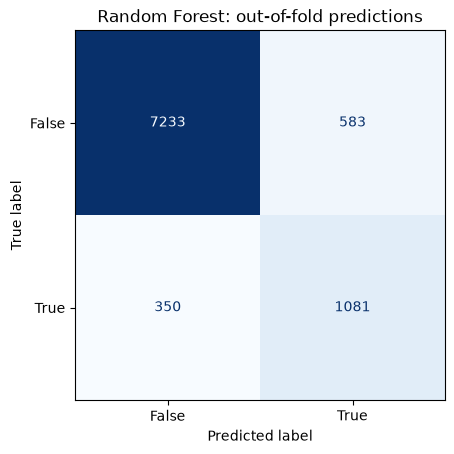

Final selection rationale should cite CV F1, its variation, F1 gap, fit time, and model complexity.


In [7]:
comparison_df = pd.concat([baseline_df, tuned_df], ignore_index=True, sort=False)
display(comparison_df.sort_values('CV_F1', ascending=False).reset_index(drop=True).round(4))

final_model_name = tuned_df.iloc[0]['Model']
final_model = clone(searches[final_model_name].best_estimator_)
print(f'Selected model: {final_model_name}')
print('Best parameters:', searches[final_model_name].best_params_)

# Out-of-fold predictions describe validation performance at the estimator's default threshold.
oof_predictions = cross_val_predict(final_model, X, y, cv=cv, method='predict', n_jobs=-1)
matrix = confusion_matrix(y, oof_predictions, labels=[False, True])
print('Out-of-fold confusion matrix [[TN, FP], [FN, TP]]:')
print(matrix)
print(classification_report(y, oof_predictions, target_names=['Revenue=False', 'Revenue=True'], digits=4))
ConfusionMatrixDisplay(matrix, display_labels=['False', 'True']).plot(cmap='Blues', colorbar=False)
plt.title(f'{final_model_name}: out-of-fold predictions'); plt.show()

print('Final selection rationale should cite CV F1, its variation, F1 gap, fit time, and model complexity.')

## Task 6 — Generate final test predictions

In [8]:
# The test CSV is loaded only now, after the final model has been selected.
df_test = pd.read_csv(PROJECT_ROOT / 'data' / 'challenge2_test.csv')
assert ID_COLUMN in df_test.columns and TARGET not in df_test.columns
assert df_test[ID_COLUMN].is_unique and df_test[ID_COLUMN].notna().all()
X_test = df_test.drop(columns=ID_COLUMN)
assert list(X_test.columns) == list(X.columns), 'Test predictors must match training predictors.'

final_model.fit(X, y)
test_predictions = final_model.predict(X_test).astype(bool)
submission = pd.DataFrame({
    ID_COLUMN: df_test[ID_COLUMN].to_numpy(),
    TARGET: np.where(test_predictions, 'True', 'False'),
})

output_path = PROJECT_ROOT / 'submissions' / 'predictions.csv'
output_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(output_path, index=False)

assert submission.columns.tolist() == [ID_COLUMN, TARGET]
assert len(submission) == len(df_test)
assert submission[ID_COLUMN].equals(df_test[ID_COLUMN].reset_index(drop=True))
assert submission[ID_COLUMN].is_unique
assert submission[TARGET].isin(['True', 'False']).all()
print(f'Saved {len(submission):,} predictions to {output_path}')
display(submission.head())

Saved 3,083 predictions to /Users/borismino/Desktop/Fall_2026/CAI4105_2026_FALL_TEAM_1/challenge2/submissions/predictions.csv


,ID,Revenue
0,2,False
1,5,False
2,6,False
3,8,False
4,10,False
